NAME-NIKHIL SINGH
CLASS-C3
ROLL NO.-C3-32

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)



In [3]:
df = pd.read_excel("Raisin_Dataset.xlsx")

In [5]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [6]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [8]:
df.shape


(900, 8)

In [9]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [12]:
df.isnull().sum()

,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0
Class,0


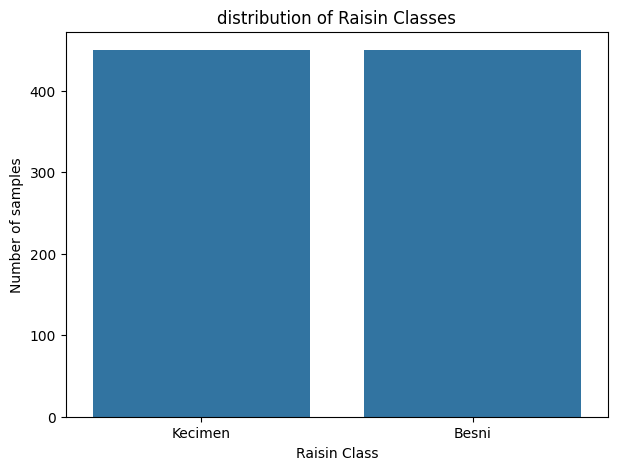

In [13]:
plt.figure(figsize=(7,5))
sns.countplot(data=df,x="Class")

plt.title("distribution of Raisin Classes")
plt.xlabel("Raisin Class")
plt.ylabel("Number of samples")
plt.show()

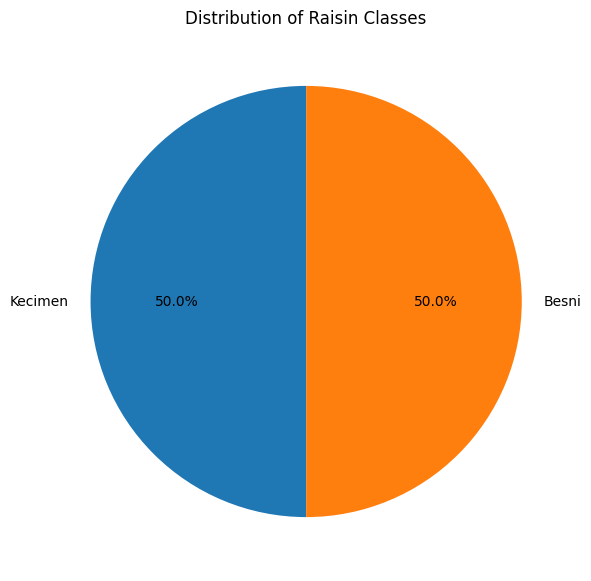

In [16]:
#pie chart
class_counts = df['Class'].value_counts()
plt.figure(figsize=(7,7))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Raisin Classes')
plt.show()

In [18]:
numerical_features = df.select_dtypes(include=np.number).columns

print("Numerical_features:")
print(numerical_features.tolist())

Numerical_features:
['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']


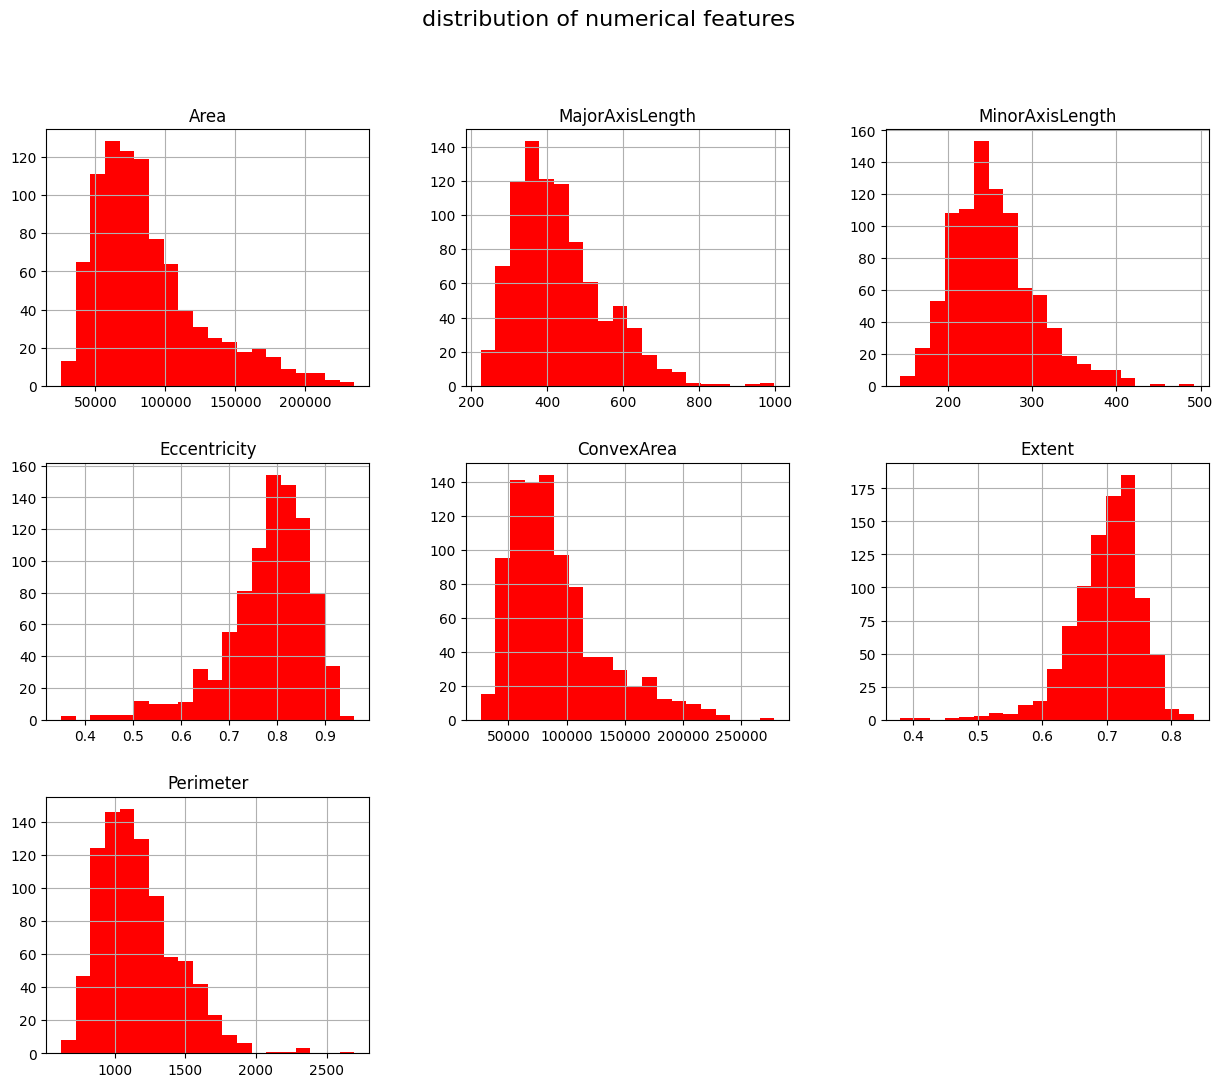

In [24]:
#histogram
df[numerical_features].hist(figsize=(15,12),bins=20,color='red')
plt.suptitle("distribution of numerical features",fontsize=16)
plt.tight_layout
plt.show()

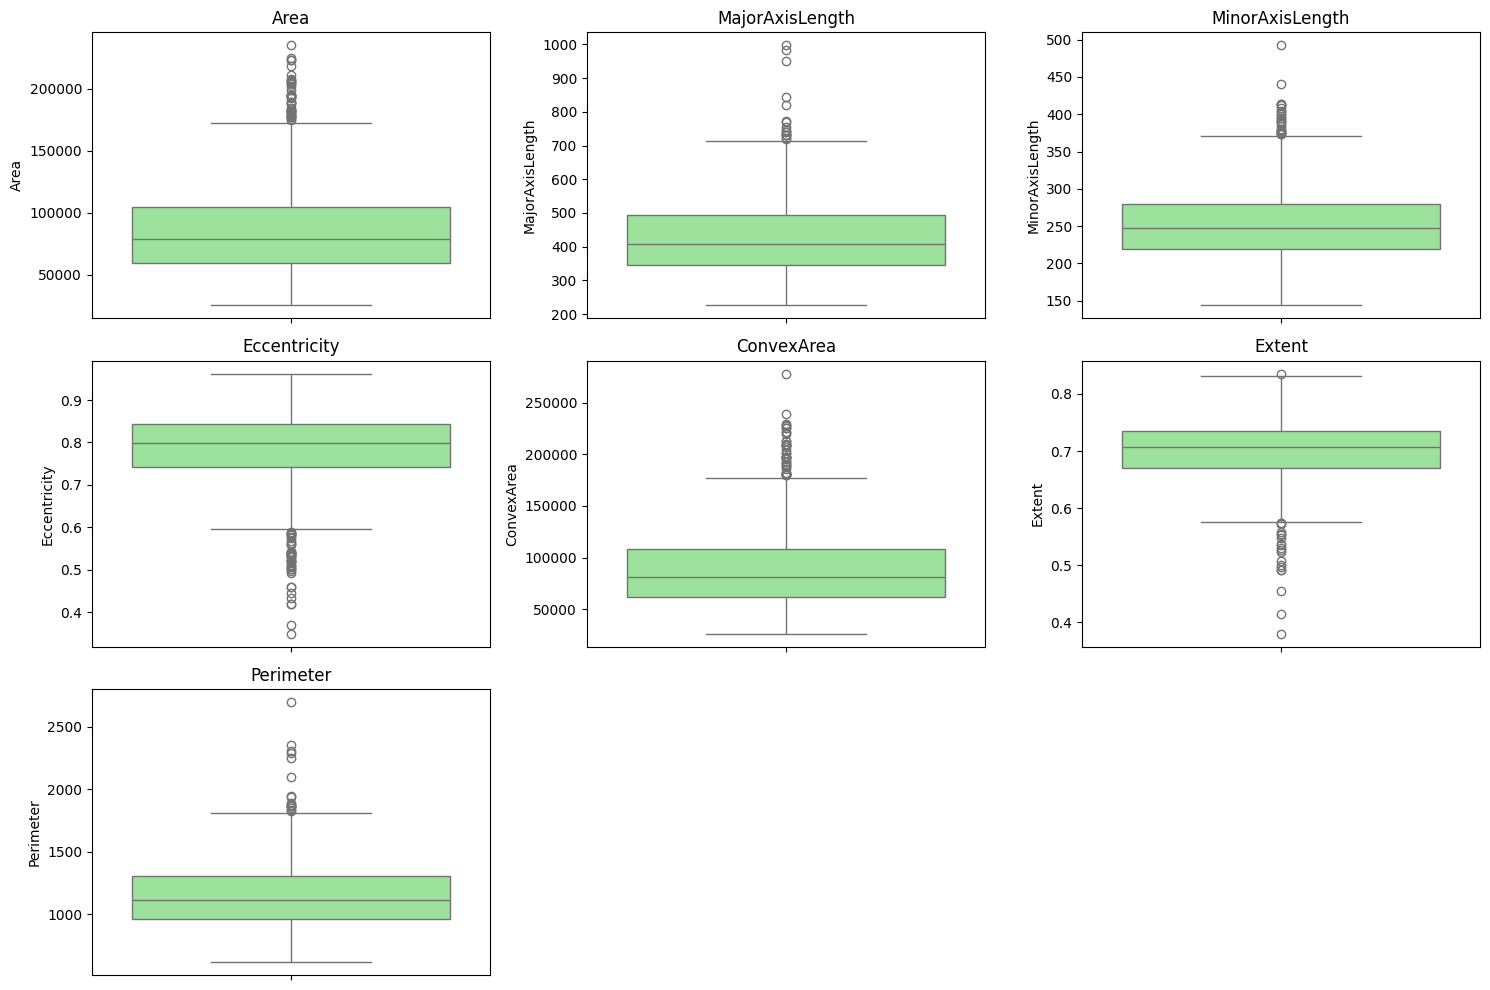

In [32]:
#boxplot

plt.figure(figsize=(15,10))

for i,column in enumerate(numerical_features,1):
    plt.subplot(3,3,i)
    sns.boxplot(y=df[column],color='lightgreen')
    plt.title(column)
    plt.tight_layout()
plt.show()

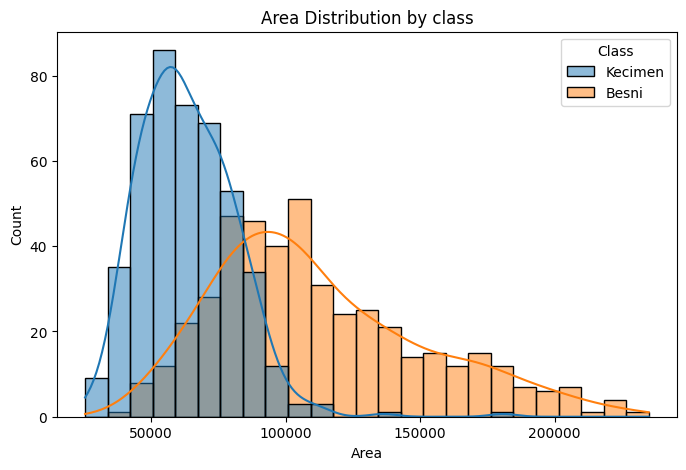

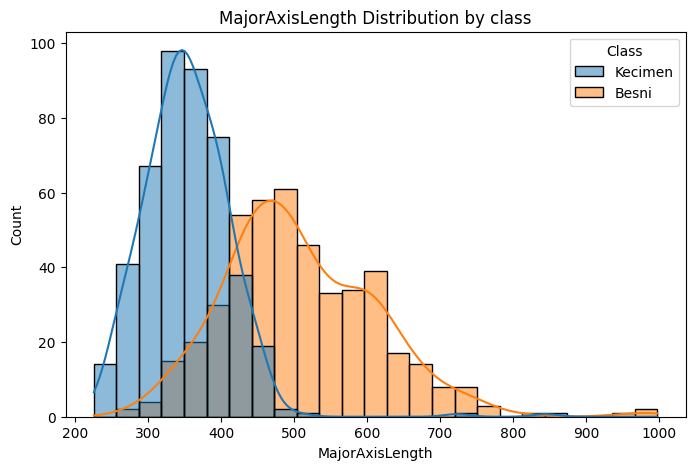

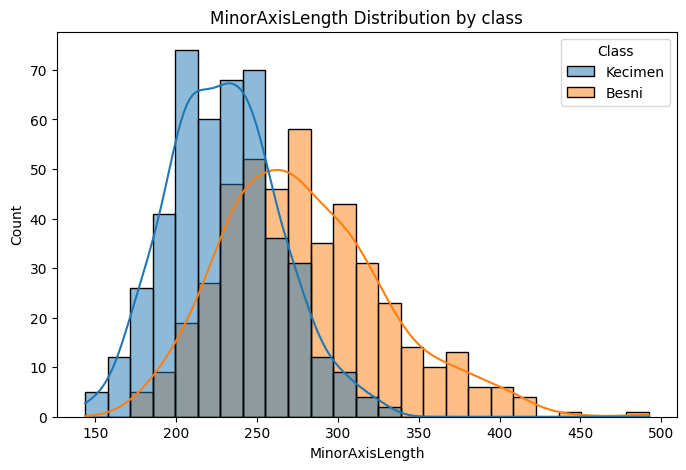

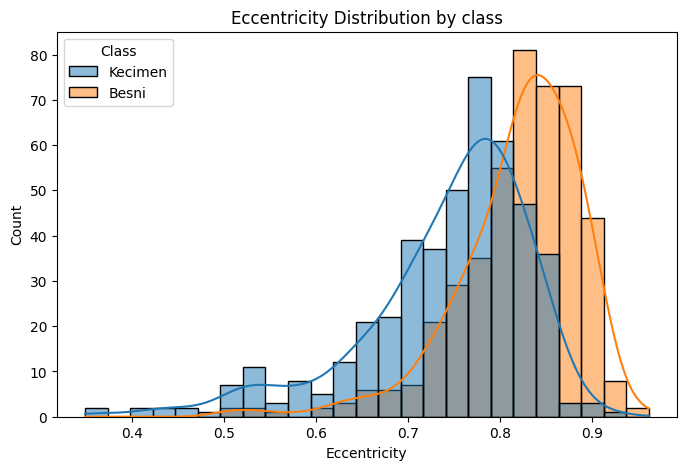

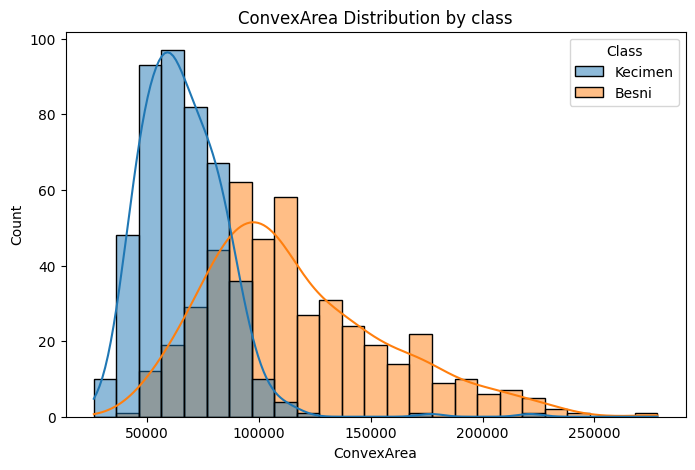

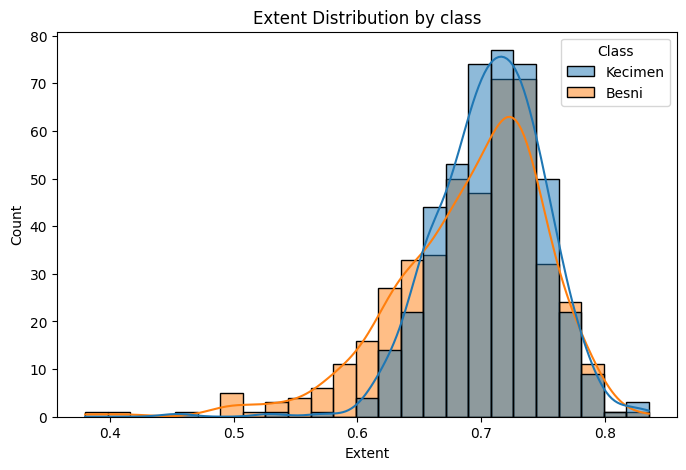

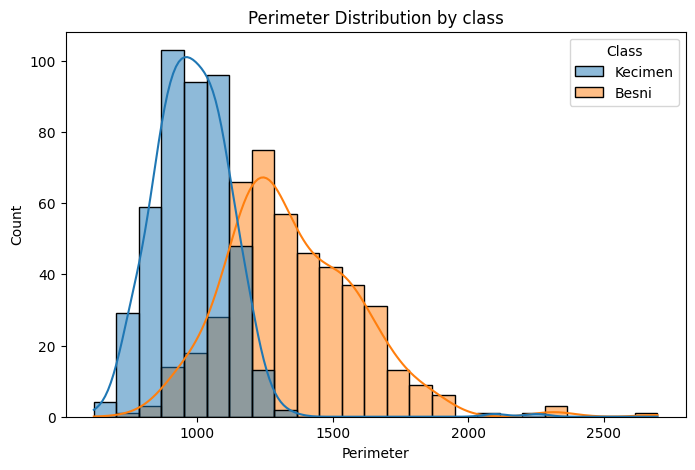

In [33]:
#histogram with kde function

for column in numerical_features:
    plt.figure(figsize=(8,5))
    sns.histplot(data=df,x=column,kde=True,hue="Class",bins=25)
    plt.title(f"{column} Distribution by class")
    plt.show()

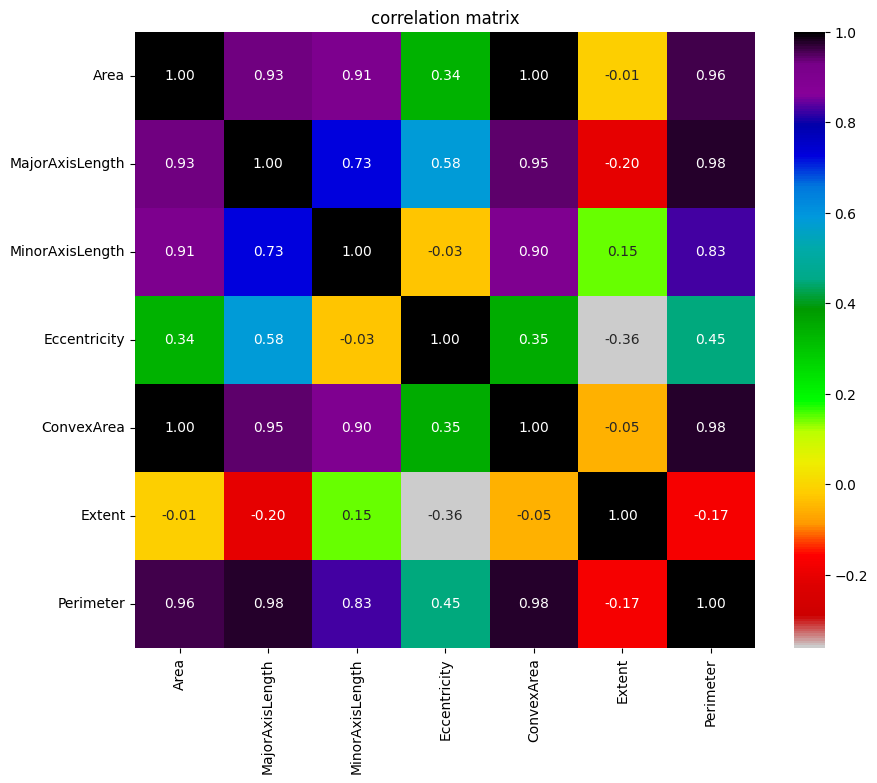

In [34]:
#correlation matrix

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="nipy_spectral_r")
plt.title("correlation matrix")
plt.show()

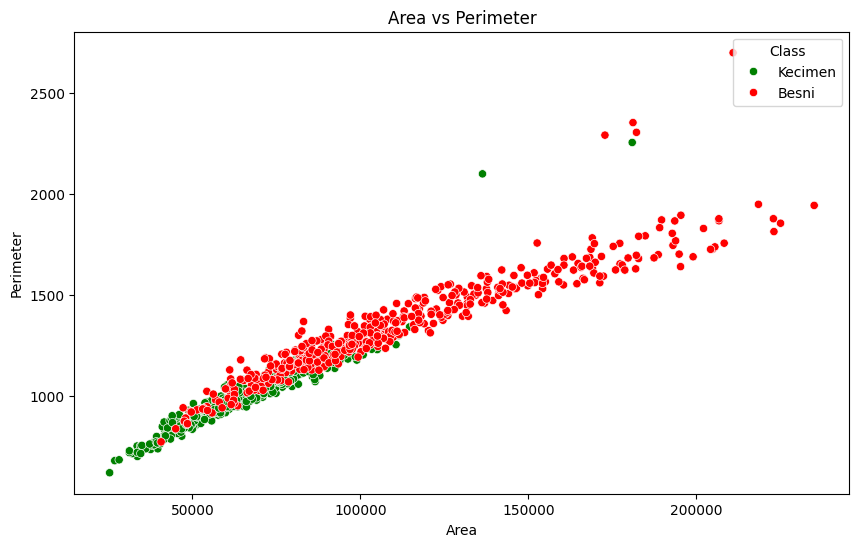

In [36]:
#scatterplot

plt.figure(figsize=(10,6))

sns.scatterplot(data=df,x="Area",y="Perimeter",hue="Class", palette={'Kecimen': 'Green', 'Besni': 'Red'})
plt.title("Area vs Perimeter")
plt.show()

In [38]:
label_encoder = LabelEncoder()
df["Class_encoded"] = label_encoder.fit_transform(df["Class"])
print(df[["Class","Class_encoded"]].head(10))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1
5  Kecimen              1
6  Kecimen              1
7  Kecimen              1
8  Kecimen              1
9  Kecimen              1


In [40]:
X = df[numerical_features]

y = df["Class_encoded"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (900, 7)
y shape: (900,)


In [41]:
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.2,random_state=42)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 720
Testing samples: 180


In [42]:
GaussianNB()

GaussianNB()

In [43]:
gnb = GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [44]:
y_pred = gnb.predict(X_test)
print("predicted labels:")
print(y_pred)

predicted labels:
[0 1 1 0 1 1 1 1 1 1 0 0 0 1 0 0 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 0 0 0 0 1
 0 1 1 1 1 1 1 0 0 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0 0 1 1 0 0 1 1
 0 0 1 1 1 0 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0 1 1 1 0 0 0 1 0 1 1 1 0 1 1 1 0
 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 1 0 1 0 1
 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 1]


In [45]:
comparison = pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
print(comparison.head(20))

     Actual  Predicted
70        1          0
827       0          1
231       1          1
588       0          0
39        1          1
731       0          1
299       1          1
110       1          1
72        1          1
86        1          1
139       1          0
533       0          0
801       0          0
120       1          1
711       0          0
590       0          0
168       1          0
422       1          1
447       1          1
67        1          0


In [46]:
comparison["Actual_Class"] = label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted_Class"] = label_encoder.inverse_transform(comparison["Predicted"])
print(comparison.head(20))

     Actual  Predicted Actual_Class Predicted_Class
70        1          0      Kecimen           Besni
827       0          1        Besni         Kecimen
231       1          1      Kecimen         Kecimen
588       0          0        Besni           Besni
39        1          1      Kecimen         Kecimen
731       0          1        Besni         Kecimen
299       1          1      Kecimen         Kecimen
110       1          1      Kecimen         Kecimen
72        1          1      Kecimen         Kecimen
86        1          1      Kecimen         Kecimen
139       1          0      Kecimen           Besni
533       0          0        Besni           Besni
801       0          0        Besni           Besni
120       1          1      Kecimen         Kecimen
711       0          0        Besni           Besni
590       0          0        Besni           Besni
168       1          0      Kecimen           Besni
422       1          1      Kecimen         Kecimen
447       1 

In [47]:
accuracy = accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.8277777777777777
Accuracy (%): 82.77777777777777


In [48]:
precision = precision_score(y_test,y_pred)
print("Precision:",precision)
print("Precision (%):", precision * 100)

Precision: 0.7889908256880734
Precision (%): 78.89908256880734


In [49]:
recall = recall_score(y_test,y_pred)
print("Recall:",recall)
print("Recall (%):", recall * 100)

Recall: 0.9148936170212766
Recall (%): 91.48936170212765


In [50]:
f1= f1_score(y_test,y_pred)
print("F1 Score:",f1)
print("F1 Score (%):", f1 * 100)

F1 Score: 0.8472906403940886
F1 Score (%): 84.72906403940887


In [51]:
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=label_encoder.classes_))

Classification Report:
              precision    recall  f1-score   support

       Besni       0.89      0.73      0.80        86
     Kecimen       0.79      0.91      0.85        94

    accuracy                           0.83       180
   macro avg       0.84      0.82      0.82       180
weighted avg       0.84      0.83      0.83       180



In [52]:
cm =  confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[63 23]
 [ 8 86]]


In [54]:
from sklearn.metrics import accuracy_score

y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)

train_accuracy = accuracy_score(y_train,y_train_pred)
test_accuracy = accuracy_score(y_test,y_test_pred)
print("Training Accuracy:",train_accuracy)
print("Testing Accuracy:",test_accuracy)

Training Accuracy: 0.8222222222222222
Testing Accuracy: 0.8277777777777777
